In [39]:
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


In [40]:
DATA_FILE = "sales_data_sample.csv"

df = pd.read_csv(DATA_FILE, encoding="latin1")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset loaded successfully!

Dataset Shape:
(2823, 25)

Column Names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

First 5 Rows:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [41]:
# Select numeric columns
X = df.select_dtypes(include="number").copy()

# Remove columns that are likely identifiers
X = X.drop(
    columns=[
        "ORDERNUMBER",
        "ORDERLINENUMBER"
    ],
    errors="ignore"
)

print("Selected Numerical Features:")
print(X.columns.tolist())

print("\nFeature Matrix Shape:")
print(X.shape)

Selected Numerical Features:
['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'MSRP']

Feature Matrix Shape:
(2823, 7)


In [42]:
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values handled successfully!")

print("\nRemaining Missing Values:")
print(X.isnull().sum().sum())

Missing values handled successfully!

Remaining Missing Values:
0


In [43]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

print("Scaled Data Shape:", X_scaled.shape)

Feature scaling completed!
Scaled Data Shape: (2823, 7)


In [44]:
inertias = []

ks = range(1, 11)

for k in ks:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    km.fit(X_scaled)

    inertias.append(km.inertia_)

print("Inertia values:")
print(inertias)

Inertia values:
[19760.999999999996, 14564.928586859576, 11567.180251282514, 9987.083347245441, 8857.599200203218, 8003.942886044376, 7445.840353865474, 6965.687412197026, 6640.72520329007, 6306.5600149409565]


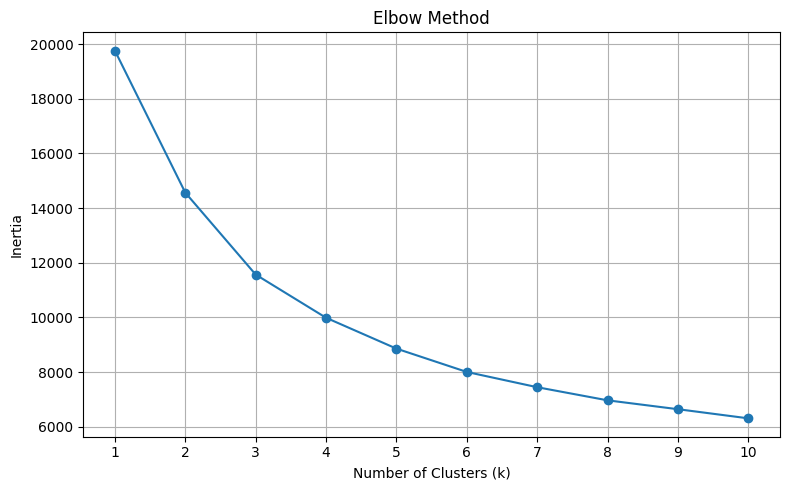

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(ks),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.xticks(list(ks))
plt.grid(True)

plt.tight_layout()
plt.show()

In [46]:
k = int(input("Choose k after inspecting the elbow plot: "))

if k < 2 or k > 10:
    raise ValueError("Please choose k between 2 and 10.")

print("Selected Number of Clusters:", k)

Selected Number of Clusters: 3


In [47]:
model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

clusters = model.fit_predict(X_scaled)

df["Cluster"] = clusters

print("K-Means clustering completed successfully!")

K-Means clustering completed successfully!


In [48]:
print("Customer Cluster Distribution:")

print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)

Customer Cluster Distribution:
Cluster
0    1043
1     850
2     930
Name: count, dtype: int64


In [49]:
print("Final Dataset with Cluster Labels:")

display(df.head(10))

print("\nCluster Summary:")

display(
    df.groupby("Cluster")[X.columns].mean().round(2)
)

Final Dataset with Cluster Labels:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,Cluster
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small,2
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small,1
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium,0
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium,0
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium,0
5,10168,36,96.66,1,3479.76,10/28/2003 0:00,Shipped,4,10,2003,...,NaN,Burlingame,CA,94217,USA,NaN,Hirano,Juri,Medium,0
6,10180,29,86.13,9,2497.77,11/11/2003 0:00,Shipped,4,11,2003,...,NaN,Lille,NaN,59000,France,EMEA,Rance,Martine,Small,0
7,10188,48,100.00,1,5512.32,11/18/2003 0:00,Shipped,4,11,2003,...,NaN,Bergen,NaN,N 5804,Norway,EMEA,Oeztan,Veysel,Medium,0
8,10201,22,98.57,2,2168.54,12/1/2003 0:00,Shipped,4,12,2003,...,NaN,San Francisco,CA,NaN,USA,NaN,Murphy,Julie,Small,0
9,10211,41,100.00,14,4708.44,1/15/2004 0:00,Shipped,1,1,2004,...,NaN,Paris,NaN,75016,France,EMEA,Perrier,Dominique,Medium,2



Cluster Summary:


,QUANTITYORDERED,PRICEEACH,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
Cluster,,,,,,,
0,35.51,97.40,4491.45,3.61,9.77,2003.52,124.02
1,33.30,60.54,1992.14,3.12,8.33,2003.62,63.89
2,36.26,89.37,3929.81,1.35,2.96,2004.33,108.24
